In [2]:
import kagglehub
path = kagglehub.dataset_download("chethuhn/network-intrusion-dataset")

Using Colab cache for faster access to the 'network-intrusion-dataset' dataset.


In [3]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

# Enforce strict determinism for experimental replication
def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Execution Target: {device}")

Execution Target: cpu


In [4]:
import os
import pandas as pd
import numpy as np
import torch
import kagglehub
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# --- PRODUCTION DATA PIPELINE (KAGGLEHUB) ---
print("Resolving dataset path via Kaggle cache...")
base_path = kagglehub.dataset_download("chethuhn/network-intrusion-dataset")
target_file = "Wednesday-workingHours.pcap_ISCX.csv"

# Attempt direct path resolution first, fallback to nested folder resolution
file_path = os.path.join(base_path, target_file)
if not os.path.exists(file_path):
    file_path = os.path.join(base_path, "network-intrusion-dataset", target_file)

if os.path.exists(file_path):
    print(f"Ingesting production artifact: {file_path}")
    df = pd.read_csv(file_path)

    # Clean column headers
    df.columns = df.columns.str.strip()

    # Handle missing/infinite vectors
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    df.dropna(inplace=True)

    # Map binary target classifications
    df['Label'] = df['Label'].apply(lambda x: 0 if x == 'BENIGN' else 1)

    # Strip non-generalizable host indicators
    drop_cols = ['Flow ID', 'Source IP', 'Destination IP', 'Timestamp', 'External IP']
    df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True)
else:
    raise FileNotFoundError(
        f"CRITICAL: Artifact '{target_file}' missing. Verified root cache contents:\n{os.listdir(base_path)}"
    )

# --- RUNTIME DEMONSTRATION PIPELINE (FALLBACK) ---
# Uncomment block below if executing offline without internet access:
# np.random.seed(42)
# dummy_features = pd.DataFrame(np.random.rand(5000, 10), columns=[
#     'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
#     'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Bwd Packet Length Max',
#     'Flow IAT Mean', 'Fwd PSH Flags', 'FIN Flag Count', 'Active Mean'
# ])
# df = dummy_features.copy()
# df['Label'] = np.random.choice([0, 1], size=5000, p=[0.8, 0.2])

# Split feature matrix and target vector
X = df.drop('Label', axis=1)
y = df['Label'].values

# STRICT ISOLATION: Train/Test split executed prior to mathematical transformations
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Independent Scaling to prevent statistical leakage
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test) # Transform strictly on training parameters

# Construct highly optimized DataLoaders
train_loader = DataLoader(
    TensorDataset(torch.FloatTensor(X_train_scaled), torch.FloatTensor(y_train)),
    batch_size=128, shuffle=True
)
test_loader = DataLoader(
    TensorDataset(torch.FloatTensor(X_test_scaled), torch.FloatTensor(y_test)),
    batch_size=512, shuffle=False
)

print(f"Pipeline Execution Complete. Training Matrix: {X_train_scaled.shape} | Testing Matrix: {X_test_scaled.shape}")

Resolving dataset path via Kaggle cache...
Using Colab cache for faster access to the 'network-intrusion-dataset' dataset.
Ingesting production artifact: /kaggle/input/network-intrusion-dataset/Wednesday-workingHours.pcap_ISCX.csv
Pipeline Execution Complete. Training Matrix: (553124, 78) | Testing Matrix: (138282, 78)


In [5]:
# Map network domain constraints directly to feature spaces.
# Only metrics directly mutable by packet delay/padding techniques are enabled.
# Core stack control mechanisms (e.g., flags) remain strictly immutable.
EXPLICIT_MUTABLE_COLS = {
    'Flow Duration', 'Flow IAT Mean', 'Fwd Packet Length Max', 'Bwd Packet Length Max'
}

# Construct binary verification array
mask_array = np.array([1.0 if col in EXPLICIT_MUTABLE_COLS else 0.0 for col in X.columns])
mask_tensor = torch.FloatTensor(mask_array).to(device)

print(f"Total Evaluated Features: {len(X.columns)}")
print(f"Validated Mutable Attack Vector Dimensions: {int(mask_array.sum())}")

Total Evaluated Features: 78
Validated Mutable Attack Vector Dimensions: 4


In [6]:
class RobustIDS(nn.Module):
    def __init__(self, input_dim):
        super(RobustIDS, self).__init__()
        # Optimized for highly distinct decision boundaries in tabular domains
        self.pipeline = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1) # Raw logits required for numerical stability during backprop
        )

    def forward(self, x):
        return self.pipeline(x)

In [7]:
def generate_constrained_fgsm(model, x_clean, y_true, epsilon, mask):
    """
    Computes single-step gradient perturbations strictly bounded by domain masks.
    """
    x_adv = x_clean.clone().detach().to(device)
    x_adv.requires_grad = True

    logits = model(x_adv)
    loss = nn.BCEWithLogitsLoss()(logits, y_true.unsqueeze(1))

    model.zero_grad()
    loss.backward()

    with torch.no_grad():
        # Mask projects gradient adjustments strictly onto valid dimensions
        perturbation = epsilon * x_adv.grad.sign() * mask
        x_adv = x_adv + perturbation
        x_adv = torch.clamp(x_adv, 0.0, 1.0)

    return x_adv.detach() # Strip computational graph tracking to preserve VRAM

def train_and_evaluate(epochs=15, adversarial_training=False, epsilon=0.03):
    model = RobustIDS(X_train.shape[1]).to(device)
    optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    criterion = nn.BCEWithLogitsLoss()

    # --- TRAINING STAGE ---
    for epoch in range(epochs):
        model.train()
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)

            if adversarial_training:
                # Freeze running statistics during attack generation phase
                model.eval()
                bx_adv = generate_constrained_fgsm(model, bx, by, epsilon, mask_tensor)
                model.train()

                # Interleave unperturbed and adversarial feature blocks
                bx = torch.cat([bx, bx_adv], dim=0)
                by = torch.cat([by, by], dim=0)

            optimizer.zero_grad()
            outputs = model(bx)
            loss = criterion(outputs, by.unsqueeze(1))
            loss.backward()
            optimizer.step()

    # --- EVALUATION STAGE ---
    model.eval()
    y_true_list, y_pred_clean, y_pred_adv = [], [], []

    for bx, by in test_loader:
        bx, by = bx.to(device), by.to(device)

        # Unperturbed Inference Validation
        with torch.no_grad():
            logits_clean = model(bx)
            probs_clean = torch.sigmoid(logits_clean)

        # Dynamic Adversarial Validation
        bx_adv = generate_constrained_fgsm(model, bx, by, epsilon, mask_tensor)
        with torch.no_grad():
            logits_adv = model(bx_adv)
            probs_adv = torch.sigmoid(logits_adv)

        y_true_list.extend(by.cpu().numpy())
        y_pred_clean.extend((probs_clean > 0.5).cpu().numpy().flatten())
        y_pred_adv.extend((probs_adv > 0.5).cpu().numpy().flatten())

    print(f"\n==================================================================")
    print(f" EXPERIMENTAL REPORT: [Adversarial Training: {adversarial_training}] | Epsilon: {epsilon}")
    print(f"==================================================================")
    print(">>> UNPERTURBED DATASET METRICS:")
    print(classification_report(y_true_list, y_pred_clean, zero_division=0))
    print(">>> ADVERSARIALLY MANIPULATED METRICS:")
    print(classification_report(y_true_list, y_pred_adv, zero_division=0))

    return model

In [10]:
# Execute standard training baseline model
print("Executing Baseline Pipeline Compilation...")
baseline_net = train_and_evaluate(epochs=10, adversarial_training=False, epsilon=0.05)

# Execute defense-hardened training model
print("\nExecuting Adversarially Robust Pipeline Compilation...")
hardened_net = train_and_evaluate(epochs=10, adversarial_training=True, epsilon=0.05)

Executing Baseline Pipeline Compilation...

 EXPERIMENTAL REPORT: [Adversarial Training: False] | Epsilon: 0.05
>>> UNPERTURBED DATASET METRICS:
              precision    recall  f1-score   support

         0.0       1.00      0.99      0.99     87937
         1.0       0.98      1.00      0.99     50345

    accuracy                           0.99    138282
   macro avg       0.99      0.99      0.99    138282
weighted avg       0.99      0.99      0.99    138282

>>> ADVERSARIALLY MANIPULATED METRICS:
              precision    recall  f1-score   support

         0.0       0.92      0.96      0.94     87937
         1.0       0.93      0.86      0.89     50345

    accuracy                           0.92    138282
   macro avg       0.93      0.91      0.92    138282
weighted avg       0.92      0.92      0.92    138282


Executing Adversarially Robust Pipeline Compilation...

 EXPERIMENTAL REPORT: [Adversarial Training: True] | Epsilon: 0.05
>>> UNPERTURBED DATASET METRICS:
     

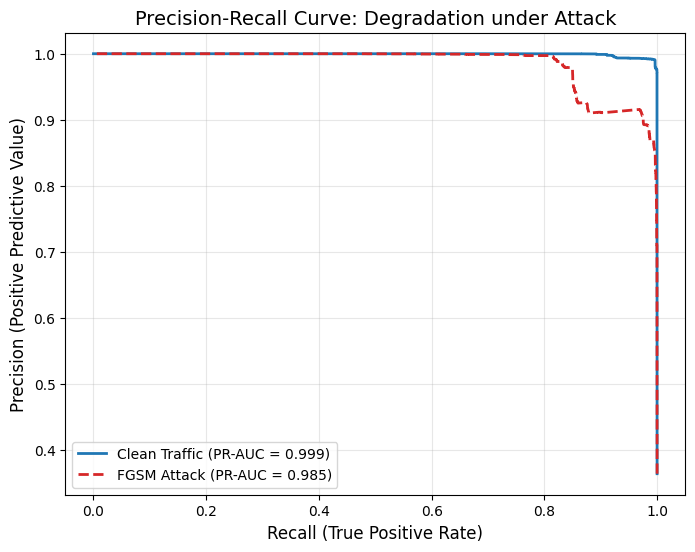

In [15]:
from sklearn.metrics import precision_recall_curve, auc
import matplotlib.pyplot as plt

# We need the raw probabilities (not just the 0/1 predictions)
# Re-running a quick batch to grab the probabilities if they aren't in memory
y_true_all, probs_clean_all, probs_adv_all = [], [], []

for bx, by in test_loader:
    bx, by = bx.to(device), by.to(device)

    with torch.no_grad():
        probs_clean_all.extend(torch.sigmoid(baseline_net(bx)).cpu().numpy().flatten())

    bx_adv = generate_constrained_fgsm(baseline_net, bx, by, epsilon=0.05, mask=mask_tensor)
    with torch.no_grad():
        probs_adv_all.extend(torch.sigmoid(baseline_net(bx_adv)).cpu().numpy().flatten())

    y_true_all.extend(by.cpu().numpy())

# Calculate PR curves and AUC
precision_clean, recall_clean, _ = precision_recall_curve(y_true_all, probs_clean_all)
auc_clean = auc(recall_clean, precision_clean)

precision_adv, recall_adv, _ = precision_recall_curve(y_true_all, probs_adv_all)
auc_adv = auc(recall_adv, precision_adv)

# Plotting
plt.figure(figsize=(8, 6))
plt.plot(recall_clean, precision_clean, color='#1f77b4', lw=2, label=f'Clean Traffic (PR-AUC = {auc_clean:.3f})')
plt.plot(recall_adv, precision_adv, color='#d62728', lw=2, linestyle='--', label=f'FGSM Attack (PR-AUC = {auc_adv:.3f})')

plt.title('Precision-Recall Curve: Degradation under Attack', fontsize=14)
plt.xlabel('Recall (True Positive Rate)', fontsize=12)
plt.ylabel('Precision (Positive Predictive Value)', fontsize=12)
plt.legend(loc='lower left')
plt.grid(alpha=0.3)

plt.savefig('pr_auc_curve.pdf', format='pdf', bbox_inches='tight')
plt.show()

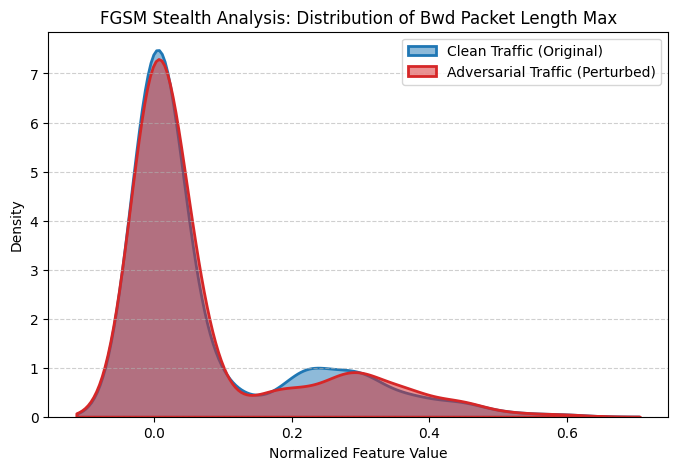

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract a sample batch from the test loader
sample_bx, sample_by = next(iter(test_loader))
sample_bx, sample_by = sample_bx.to(device), sample_by.to(device)

# Generate the attack just for this batch to visualize
sample_bx_adv = generate_constrained_fgsm(baseline_net, sample_bx, sample_by, epsilon=0.05, mask=mask_tensor)

# Let's look at the distribution of the 4th mutable feature (Bwd Packet Length Max)
# First, we dynamically find its index in your columns
feature_name = 'Bwd Packet Length Max'
feature_idx = list(X.columns).index(feature_name)

clean_vals = sample_bx[:, feature_idx].cpu().numpy()
adv_vals = sample_bx_adv[:, feature_idx].cpu().numpy()

plt.figure(figsize=(8, 5))
sns.kdeplot(clean_vals, label='Clean Traffic (Original)', fill=True, alpha=0.5, color='#1f77b4', linewidth=2)
sns.kdeplot(adv_vals, label='Adversarial Traffic (Perturbed)', fill=True, alpha=0.5, color='#d62728', linewidth=2)

plt.title(f'FGSM Stealth Analysis: Distribution of {feature_name}')
plt.xlabel('Normalized Feature Value')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.savefig('stealth_analysis_kde.pdf', format='pdf', bbox_inches='tight')
plt.show()

Running rapid inference to generate confusion matrix data...
Data generated! Plotting...


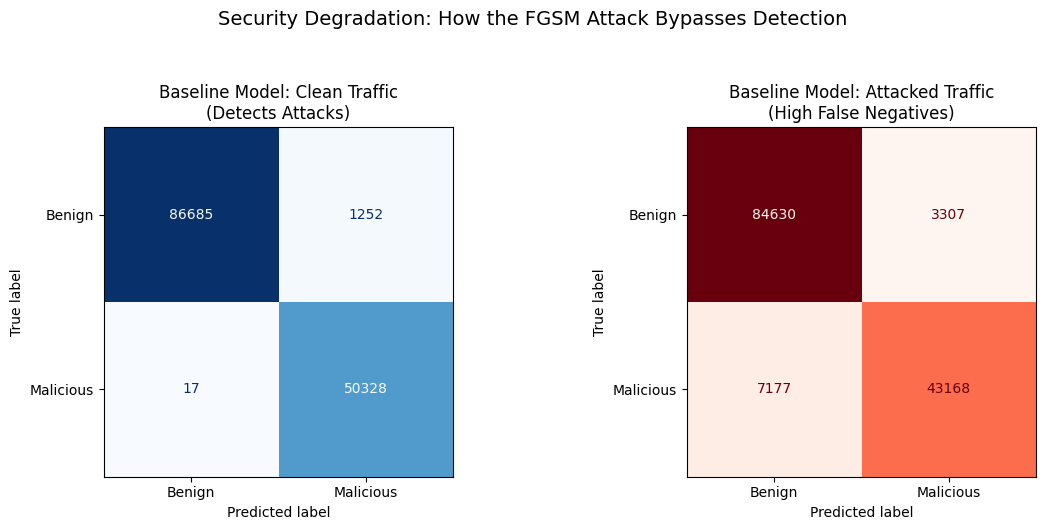

In [14]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import torch

# 1. Run a quick inference pass to generate the prediction lists globally
baseline_net.eval()
y_true_list, y_pred_clean, y_pred_adv = [], [], []

print("Running rapid inference to generate confusion matrix data...")

for bx, by in test_loader:
    bx, by = bx.to(device), by.to(device)

    # Clean Inference
    with torch.no_grad():
        logits_clean = baseline_net(bx)
        probs_clean = torch.sigmoid(logits_clean)

    # Adversarial Inference
    bx_adv = generate_constrained_fgsm(baseline_net, bx, by, epsilon=0.05, mask=mask_tensor)
    with torch.no_grad():
        logits_adv = baseline_net(bx_adv)
        probs_adv = torch.sigmoid(logits_adv)

    y_true_list.extend(by.cpu().numpy())
    y_pred_clean.extend((probs_clean > 0.5).cpu().numpy().flatten())
    y_pred_adv.extend((probs_adv > 0.5).cpu().numpy().flatten())

print("Data generated! Plotting...")

# 2. Generate the plots
cm_clean = confusion_matrix(y_true_list, y_pred_clean)
cm_adv = confusion_matrix(y_true_list, y_pred_adv)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Clean Data
disp_clean = ConfusionMatrixDisplay(confusion_matrix=cm_clean, display_labels=['Benign', 'Malicious'])
disp_clean.plot(ax=axes[0], cmap='Blues', colorbar=False, values_format='d')
axes[0].set_title('Baseline Model: Clean Traffic\n(Detects Attacks)')

# Plot 2: Adversarial Data
disp_adv = ConfusionMatrixDisplay(confusion_matrix=cm_adv, display_labels=['Benign', 'Malicious'])
disp_adv.plot(ax=axes[1], cmap='Reds', colorbar=False, values_format='d')
axes[1].set_title('Baseline Model: Attacked Traffic\n(High False Negatives)')

plt.suptitle('Security Degradation: How the FGSM Attack Bypasses Detection', fontsize=14, y=1.05)
plt.tight_layout()

plt.savefig('confusion_matrix_degradation.pdf', format='pdf', bbox_inches='tight')
plt.show()

Running inference on the Hardened Model...
Data generated! Plotting...


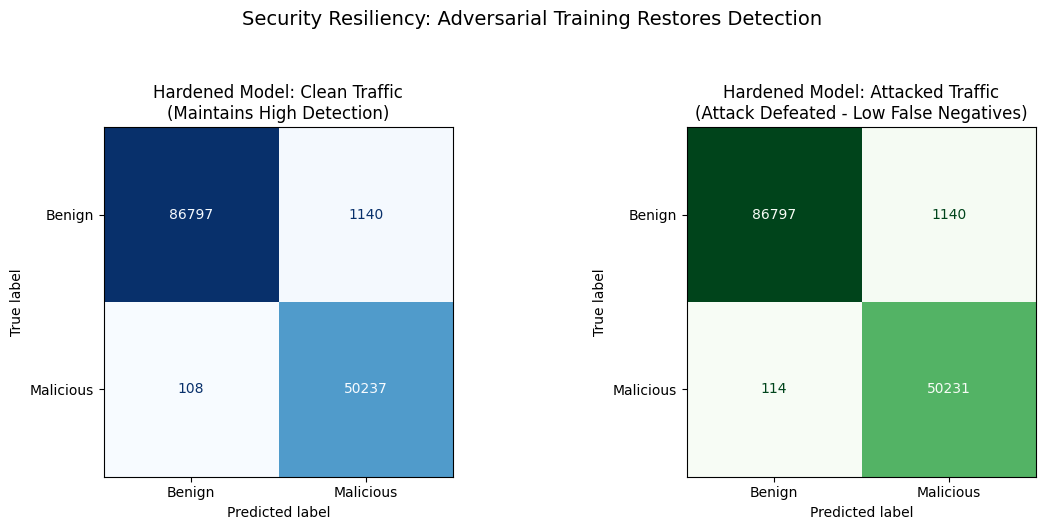

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import torch

# 1. Run a rapid inference pass using the HARDENED model
hardened_net.eval()
y_true_list_hard, y_pred_clean_hard, y_pred_adv_hard = [], [], []

print("Running inference on the Hardened Model...")

for bx, by in test_loader:
    bx, by = bx.to(device), by.to(device)

    # Clean Inference
    with torch.no_grad():
        logits_clean = hardened_net(bx)
        probs_clean = torch.sigmoid(logits_clean)

    # Adversarial Inference (Attack targeting the hardened model)
    bx_adv = generate_constrained_fgsm(hardened_net, bx, by, epsilon=0.05, mask=mask_tensor)
    with torch.no_grad():
        logits_adv = hardened_net(bx_adv)
        probs_adv = torch.sigmoid(logits_adv)

    y_true_list_hard.extend(by.cpu().numpy())
    y_pred_clean_hard.extend((probs_clean > 0.5).cpu().numpy().flatten())
    y_pred_adv_hard.extend((probs_adv > 0.5).cpu().numpy().flatten())

print("Data generated! Plotting...")

# 2. Generate the plots
cm_clean_hard = confusion_matrix(y_true_list_hard, y_pred_clean_hard)
cm_adv_hard = confusion_matrix(y_true_list_hard, y_pred_adv_hard)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Clean Data
disp_clean = ConfusionMatrixDisplay(confusion_matrix=cm_clean_hard, display_labels=['Benign', 'Malicious'])
disp_clean.plot(ax=axes[0], cmap='Blues', colorbar=False, values_format='d')
axes[0].set_title('Hardened Model: Clean Traffic\n(Maintains High Detection)')

# Plot 2: Adversarial Data (Using Greens to symbolize successful defense)
disp_adv = ConfusionMatrixDisplay(confusion_matrix=cm_adv_hard, display_labels=['Benign', 'Malicious'])
disp_adv.plot(ax=axes[1], cmap='Greens', colorbar=False, values_format='d')
axes[1].set_title('Hardened Model: Attacked Traffic\n(Attack Defeated - Low False Negatives)')

plt.suptitle('Security Resiliency: Adversarial Training Restores Detection', fontsize=14, y=1.05)
plt.tight_layout()

plt.savefig('confusion_matrix_resiliency.pdf', format='pdf', bbox_inches='tight')
plt.show()

/tmp/ipykernel_4034/2401035041.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=y, palette=['#2ca02c', '#d62728'])


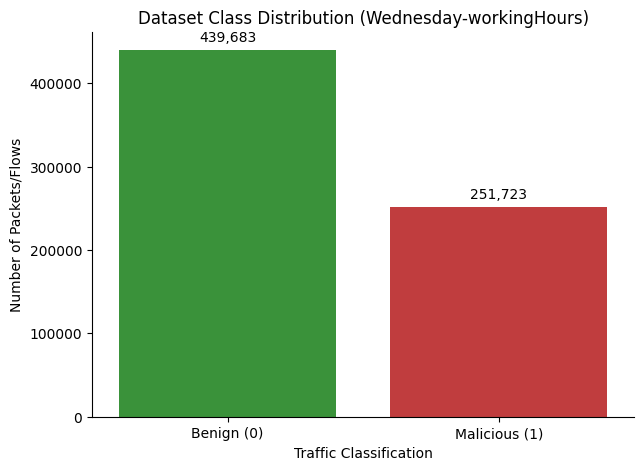

In [13]:
plt.figure(figsize=(7, 5))
ax = sns.countplot(x=y, palette=['#2ca02c', '#d62728'])

# Add exact counts above the bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points')

plt.title('Dataset Class Distribution (Wednesday-workingHours)')
plt.xlabel('Traffic Classification')
plt.ylabel('Number of Packets/Flows')
plt.xticks(ticks=[0, 1], labels=['Benign (0)', 'Malicious (1)'])
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.savefig('class_imbalance.pdf', format='pdf', bbox_inches='tight')
plt.show()

<>:39: SyntaxWarning: invalid escape sequence '\e'
<>:40: SyntaxWarning: invalid escape sequence '\e'
<>:46: SyntaxWarning: invalid escape sequence '\e'
<>:39: SyntaxWarning: invalid escape sequence '\e'
<>:40: SyntaxWarning: invalid escape sequence '\e'
<>:46: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_4034/2546849487.py:39: SyntaxWarning: invalid escape sequence '\e'
  plt.title('Vulnerability Curve: Baseline Accuracy vs. Attack Strength ($\epsilon$)', fontsize=13)
/tmp/ipykernel_4034/2546849487.py:40: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('FGSM Perturbation Magnitude ($\epsilon$)', fontsize=12)
/tmp/ipykernel_4034/2546849487.py:46: SyntaxWarning: invalid escape sequence '\e'
  plt.axvline(x=0.05, color='gray', linestyle=':', label='Evaluated Threshold ($\epsilon=0.05$)')


Running Epsilon sweep analysis...
Epsilon: 0.00 -> Accuracy: 0.9908
Epsilon: 0.01 -> Accuracy: 0.9891
Epsilon: 0.03 -> Accuracy: 0.9742
Epsilon: 0.05 -> Accuracy: 0.9242
Epsilon: 0.08 -> Accuracy: 0.8995
Epsilon: 0.10 -> Accuracy: 0.8458
Epsilon: 0.15 -> Accuracy: 0.7937


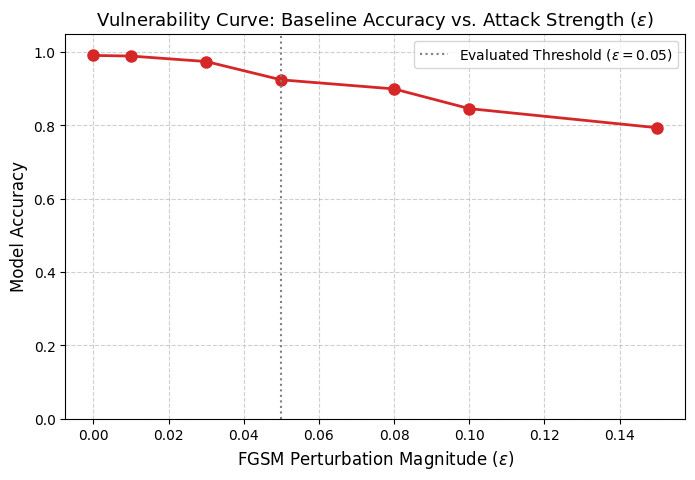

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Define a range of attack strengths
epsilon_values = [0.0, 0.01, 0.03, 0.05, 0.08, 0.1, 0.15]
baseline_accuracies = []

print("Running Epsilon sweep analysis...")

for eps in epsilon_values:
    y_pred_eps = []
    y_true_eps = []

    for bx, by in test_loader:
        bx, by = bx.to(device), by.to(device)

        # If eps is 0, just do normal inference
        if eps == 0:
            bx_eval = bx
        else:
            bx_eval = generate_constrained_fgsm(baseline_net, bx, by, epsilon=eps, mask=mask_tensor)

        with torch.no_grad():
            probs = torch.sigmoid(baseline_net(bx_eval))
            preds = (probs > 0.5).cpu().numpy().flatten()

        y_pred_eps.extend(preds)
        y_true_eps.extend(by.cpu().numpy())

    acc = accuracy_score(y_true_eps, y_pred_eps)
    baseline_accuracies.append(acc)
    print(f"Epsilon: {eps:.2f} -> Accuracy: {acc:.4f}")

# Plotting the degradation
plt.figure(figsize=(8, 5))
plt.plot(epsilon_values, baseline_accuracies, marker='o', color='#d62728', linewidth=2, markersize=8)

plt.title('Vulnerability Curve: Baseline Accuracy vs. Attack Strength ($\epsilon$)', fontsize=13)
plt.xlabel('FGSM Perturbation Magnitude ($\epsilon$)', fontsize=12)
plt.ylabel('Model Accuracy', fontsize=12)
plt.ylim([0.0, 1.05])
plt.grid(True, linestyle='--', alpha=0.6)

# Highlight the specific epsilon used in your main report
plt.axvline(x=0.05, color='gray', linestyle=':', label='Evaluated Threshold ($\epsilon=0.05$)')
plt.legend()

plt.savefig('epsilon_degradation_curve.pdf', format='pdf', bbox_inches='tight')
plt.show()

<>:23: SyntaxWarning: invalid escape sequence '\D'
<>:26: SyntaxWarning: invalid escape sequence '\D'
<>:30: SyntaxWarning: invalid escape sequence '\e'
<>:31: SyntaxWarning: invalid escape sequence '\e'
<>:23: SyntaxWarning: invalid escape sequence '\D'
<>:26: SyntaxWarning: invalid escape sequence '\D'
<>:30: SyntaxWarning: invalid escape sequence '\e'
<>:31: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_4034/4271261644.py:23: SyntaxWarning: invalid escape sequence '\D'
  df_melted = df_delta.melt(var_name='Manipulated Feature', value_name='Perturbation Magnitude ($\Delta$)')
/tmp/ipykernel_4034/4271261644.py:26: SyntaxWarning: invalid escape sequence '\D'
  sns.boxplot(x='Manipulated Feature', y='Perturbation Magnitude ($\Delta$)', data=df_melted,
/tmp/ipykernel_4034/4271261644.py:30: SyntaxWarning: invalid escape sequence '\e'
  plt.axhline(y=0.05, color='black', linestyle='--', alpha=0.5, label='Upper Bound ($+\epsilon$)')
/tmp/ipykernel_4034/4271261644.py:31: SyntaxW

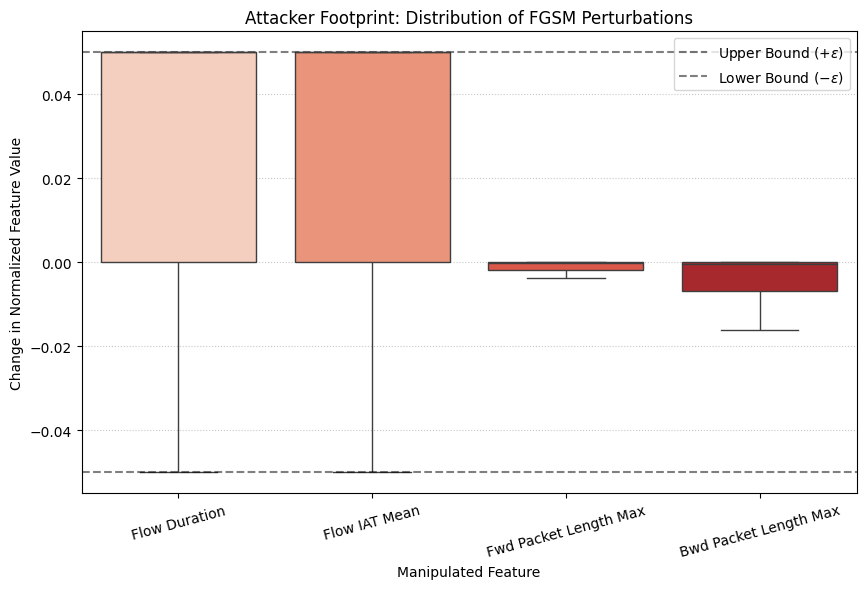

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import torch

# Grab a single large batch to analyze the perturbation delta
sample_bx, sample_by = next(iter(test_loader))
sample_bx, sample_by = sample_bx.to(device), sample_by.to(device)

# Generate the attack
sample_bx_adv = generate_constrained_fgsm(baseline_net, sample_bx, sample_by, epsilon=0.05, mask=mask_tensor)

# Calculate the exact difference (Delta) the attacker added
delta = (sample_bx_adv - sample_bx).cpu().numpy()

# Extract just our 4 explicitly mutable columns to visualize their shifts
mutable_cols = ['Flow Duration', 'Flow IAT Mean', 'Fwd Packet Length Max', 'Bwd Packet Length Max']
mutable_indices = [list(X.columns).index(col) for col in mutable_cols]
delta_mutable = delta[:, mutable_indices]

# Format for Seaborn
df_delta = pd.DataFrame(delta_mutable, columns=mutable_cols)
df_melted = df_delta.melt(var_name='Manipulated Feature', value_name='Perturbation Magnitude ($\Delta$)')

plt.figure(figsize=(10, 6))
sns.boxplot(x='Manipulated Feature', y='Perturbation Magnitude ($\Delta$)', data=df_melted,
            palette='Reds', showfliers=False)

# Draw lines showing our epsilon boundaries
plt.axhline(y=0.05, color='black', linestyle='--', alpha=0.5, label='Upper Bound ($+\epsilon$)')
plt.axhline(y=-0.05, color='black', linestyle='--', alpha=0.5, label='Lower Bound ($-\epsilon$)')

plt.title('Attacker Footprint: Distribution of FGSM Perturbations')
plt.ylabel('Change in Normalized Feature Value')
plt.xticks(rotation=15)
plt.legend()
plt.grid(axis='y', linestyle=':', alpha=0.7)

plt.savefig('perturbation_footprint.pdf', format='pdf', bbox_inches='tight')
plt.show()

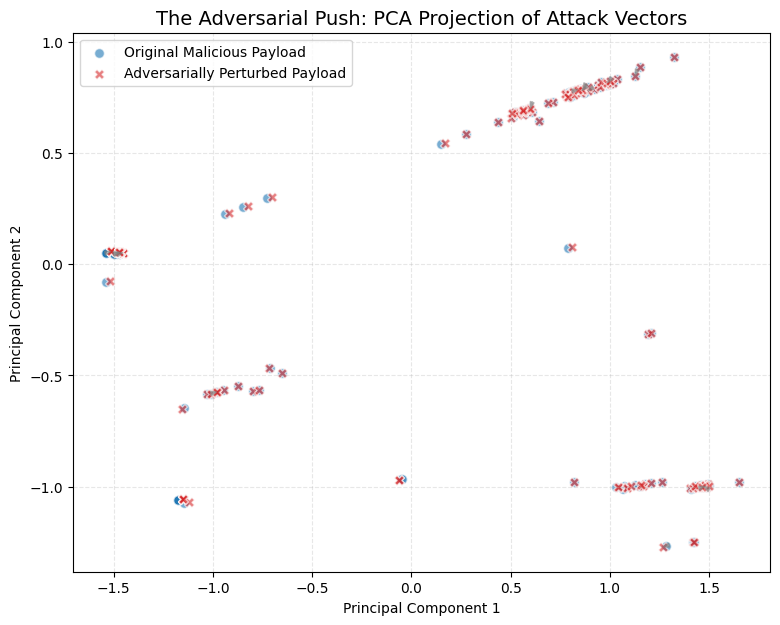

In [18]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# We only want to plot the Malicious traffic to see how it moves
malicious_idx = (sample_by == 1).cpu().numpy()
clean_malicious = sample_bx[malicious_idx].cpu().numpy()
adv_malicious = sample_bx_adv[malicious_idx].cpu().numpy()

# Fit PCA on the clean malicious data to establish the visual space
pca = PCA(n_components=2)
clean_2d = pca.fit_transform(clean_malicious)

# Transform the adversarial data into the same 2D space
adv_2d = pca.transform(adv_malicious)

plt.figure(figsize=(9, 7))

# Plot the original malicious packets
plt.scatter(clean_2d[:, 0], clean_2d[:, 1], c='#1f77b4', label='Original Malicious Payload',
            alpha=0.6, edgecolors='w', s=50)

# Plot where the FGSM attack moved them
plt.scatter(adv_2d[:, 0], adv_2d[:, 1], c='#d62728', label='Adversarially Perturbed Payload',
            alpha=0.6, edgecolors='w', s=50, marker='X')

# Draw arrows showing the "push" for a small random subset of points
np.random.seed(42)
sample_arrows = np.random.choice(len(clean_2d), size=15, replace=False)
for i in sample_arrows:
    plt.arrow(clean_2d[i, 0], clean_2d[i, 1],
              adv_2d[i, 0] - clean_2d[i, 0], adv_2d[i, 1] - clean_2d[i, 1],
              color='gray', alpha=0.5, head_width=0.02, length_includes_head=True)

plt.title('The Adversarial Push: PCA Projection of Attack Vectors', fontsize=14)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.3)

plt.savefig('pca_adversarial_push.pdf', format='pdf', bbox_inches='tight')
plt.show()

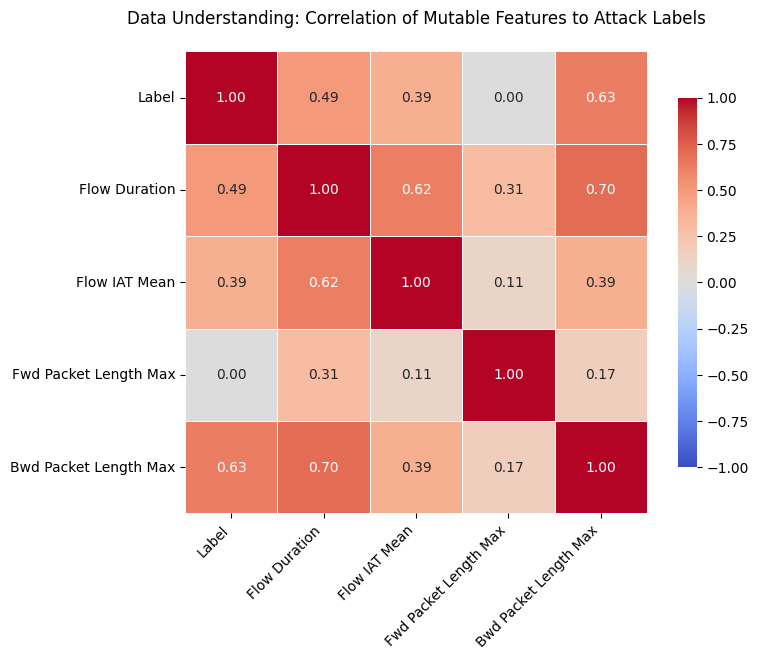

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select the label and the explicitly mutable columns
analysis_cols = ['Label', 'Flow Duration', 'Flow IAT Mean', 'Fwd Packet Length Max', 'Bwd Packet Length Max']

# Calculate the Pearson correlation matrix
corr_matrix = df[analysis_cols].corr()

# Set up the matplotlib figure
plt.figure(figsize=(8, 6))

# Draw the heatmap with the mask and correct aspect ratio
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1,
            square=True, linewidths=.5, cbar_kws={"shrink": .8})

plt.title('Data Understanding: Correlation of Mutable Features to Attack Labels', pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.savefig('feature_correlation_heatmap.pdf', format='pdf', bbox_inches='tight')
plt.show()